# アルゴリズム論Ⅱ 

## 第3回：ニュートン法（1）

このノートブックでは、関数の**微分**（接線の傾き）を利用して**超ハイスピードで方程式の解を突き止める**ニュートン法（Newton-Raphson法）について学びます。

前回（第2回）学んだ「二分法」は、解を確実に挟み込んで地道に範囲を半分にしていく「安心・安全な方法」でした。
一方、今回の「ニュートン法」は、ステップごとに正しい桁数が約2倍に増えるという**圧倒的な計算スピード（二次収束）**を誇ります。

しかし、その驚異的なスピードの裏には、「**初期値の選び方**を間違えると、解が彼方に吹き飛んで大失敗する」という**強烈な落とし穴**も潜んでいます。以下のような点について学びます：

- ニュートン法はなぜこれほど速いのか（微分の幾何学的意味「接線」から理解する仕組み）
- なぜ・どのように発散するのか（$x^3 - 3x + 1 = 0$ や IRR の失敗例）
- どのような現実の問題（CPUの基本演算や電子回路の計算）で真価を発揮しているのか


---
## 1. ニュートン法の原理と仕組み（微分の幾何学的意味から理解する）

方程式 $f(x) = 0$ の解（グラフが $x$ 軸と交わる点）を求めたいとします。
ニュートン法では、適当な初期値 $x_0$ から出発して、次のような手順で解に迫ります：

> **📐 ニュートン法の幾何学的アルゴリズム**  
> 1. 現在地 $(x_k, f(x_k))$ における関数の**接線**を引く。  
> 2. その接線が **$x$ 軸と交わる点**（$x$ 切片）を次の推測値 $x_{k+1}$ とする。  
> 3. 新しい点 $(x_{k+1}, f(x_{k+1}))$ から再び接線を引いて更新する……を繰り返す！

### 接線の方程式から更新式を導く
微分積分学における「接線の方程式」を思い出してみましょう。  
曲線 $y = f(x)$ 上の点 $(x_k, f(x_k))$ における接線の傾きは、微分係数 $f'(x_k)$ ですから、接線の方程式は次式で与えられます：

$$ y - f(x_k) = f'(x_k) (x - x_k) $$

この接線が $x$ 軸と交わる点（すなわち $y = 0$ となる $x$）を次の候補 $x_{k+1}$ とおきます：

$$ 0 - f(x_k) = f'(x_k) (x_{k+1} - x_k) $$

これを $x_{k+1}$ について解くことで、ニュートン法の有名な**更新式**が得られます：

$$ x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)} $$

非常にシンプルな式ですが、これをごく数回繰り返すだけで、猛烈な速度で解に吸い寄せられていきます。

---

### 🚀 二次収束（Quadratic Convergence）の凄さ
ニュートン法の最大の特徴は、その**驚異的な収束スピード**にあります。

- **二分法（一次収束）**: 1反復ごとに区間の幅が半分（$1/2$）になる。
  - 誤差を $1/10$（精度を1桁向上）にするのに約 3.3 回の反復が必要。
- **ニュートン法（二次収束）**: 1反復ごとに**正しい有効桁数が約2倍**に倍増する！
  - 1回目：誤差 $10^{-1}$（約 1 桁正確）
  - 2回目：誤差 $10^{-2}$（約 2 桁正確）
  - 3回目：誤差 $10^{-4}$（約 4 桁正確）
  - 4回目：誤差 $10^{-8}$（約 8 桁正確）
  - 5回目：誤差 $10^{-16}$（約 16 桁正確：倍精度浮動小数点の限界に到達！）

わずか 4〜5 回の反復で、コンピュータの倍精度浮動小数点の物理限界（約 16 桁）まで到達してしまうのです。


---

### ニュートン法のアルゴリズムを図示したアニメーションで学ぶ：

<a href="https://kita-toshihiro.github.io/algoII/newton1.html" target="_blank">
    <img width="400" src ="https://kita-toshihiro.github.io/algoII/newton1.png">
</a>

https://kita-toshihiro.github.io/algoII/newton1.html

---
## 2. ニュートン法の実装：平方根 $\sqrt{2}$ で二分法と速さを対決！

実際にプログラムを動かして、第2回の「二分法」と今回の「ニュートン法」の収束スピードを直接比較してみましょう。

方程式 $f(x) = x^2 - 2 = 0$ の正の解（$\sqrt{2} \approx 1.41421356...$）を探索します：
- 導関数：$f'(x) = 2x$
- ニュートン法の更新式：
  $$ x_{k+1} = x_k - \frac{x_k^2 - 2}{2x_k} = \frac{1}{2} \left( x_k + \frac{2}{x_k} \right) $$

*(※この式は「現在の値 $x_k$」と「2を割った値 $2/x_k$」の相加平均をとる漸化式になっており、紀元前の古代バビロニアの時代から知られていたため **「バビロニア法」** とも呼ばれます)*


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 真値
true_root = math.sqrt(2)

# 1. 二分法の実装
a, b = 1.0, 2.0
bisection_errors = []
for step in range(1, 16):
    mid = (a + b) / 2.0
    err = abs(mid - true_root)
    bisection_errors.append(err)
    if mid**2 - 2.0 > 0:
        b = mid
    else:
        a = mid

# 2. ニュートン法の実装 (初期値 x0 = 2.0)
x_val = 2.0
newton_errors = []
print("=== ニュートン法による √2 の探索（真値: 1.414213562373095） ===")
print(f"初期値: x_0 = {x_val:.1f}")
print("-" * 65)

for step in range(1, 16):
    err = abs(x_val - true_root)
    newton_errors.append(max(err, 1e-16))  # 対数表示用に下限を 1e-16 に制限
    print(f"Step {step:2d}: x = {x_val:18.15f},  誤差 = {err:.3e}")
    if err < 1e-15:
        print("-" * 65)
        print(f"🎉 わずか {step} 回で倍精度浮動小数点の限界（約16桁）に完全到達！\n")
        break
    x_val = 0.5 * (x_val + 2.0 / x_val)

# 誤差推移の比較グラフ（片対数グラフ）
plt.figure(figsize=(7, 4))
plt.semilogy(range(1, len(bisection_errors) + 1), bisection_errors, 'bs--', label='二分法（一次収束: 確実に半減）', linewidth=2)
plt.semilogy(range(1, len(newton_errors) + 1), newton_errors, 'ro-', label='ニュートン法（二次収束: 爆発的に収束）', linewidth=2)

plt.title("収束スピードの比較：二分法 vs ニュートン法（対数スケール）", fontsize=13)
plt.xlabel("反復回数（ステップ）", fontsize=11)
plt.ylabel("真値との絶対誤差 |x - √2|", fontsize=11)
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend(fontsize=10.5)
plt.show()

---
## 3. ニュートン法が発散・失敗する例 (1)：$x^3 - 3x + 1 = 0$

「こんなに速いなら、すべての方程式をニュートン法で解けばよいのでは？」と思われるかもしれません。  
しかし、ニュートン法には**初期値の選び方によって激しく発散・失敗する弱点**が存在します。

第2回で二分法を用いて解いた3次方程式を取り上げてみましょう：

$$ f(x) = x^3 - 3x + 1 = 0 $$

この関数を微分してみます：
$$ f'(x) = 3x^2 - 3 = 3(x + 1)(x - 1) $$

導関数が $0$ になる点、すなわち関数の**極値（極大値・極小値）**は：
- $x = -1$（極大値: $f(-1) = 3$）
- $x = 1$（極小値: $f(1) = -1$）

この2つの極値の周辺で、ニュートン法を実行すると何が起こるでしょうか？

---

### ⚠️ 失敗パターン A：傾きゼロの点（$x_0 = 1.0$）からのスタート
極値 $x_0 = 1.0$ では、接線の傾きが水平（$f'(1.0) = 0$）になります。  
更新式を計算しようとすると：
$$ x_1 = 1.0 - \frac{f(1.0)}{f'(1.0)} = 1.0 - \frac{-1}{0} \implies \text{ゼロ除算エラー（ZeroDivisionError）！} $$
接線が水平なため $x$ 軸と交差できず、計算不能で即座にクラッシュします。

---

### ⚠️ 失敗パターン B：極値のすぐ近傍（$x_0 = 0.99$）からのスタート
「では、極値からわずかにズラした $x_0 = 0.99$ から始めれば安全だろう」と試してみましょう。  
実際に計算すると：
- $f(0.99) \approx -0.9997$
- $f'(0.99) = 3(0.99^2 - 1) = -0.0597$（傾きがゼロに極めて近い）
- 次の推測値：
  $$ x_1 = 0.99 - \frac{-0.9997}{-0.0597} \approx 0.99 - 16.745 = \mathbf{-15.755} $$

傾きが水平に近すぎるため、**接線が $x$ 軸と交わる点が遥か彼方（$-15$ 以下の遠方）へ猛烈に吹き飛ばされます！**

しかも、本来探索したかったのは $x \approx 1.53$ の正の解だったにもかかわらず、吹き飛んだ結果、**全く意図していなかった別の負の解（$x \approx -1.88$）に収束してしまう**のです。


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

def f3(x):
    return x**3 - 3*x + 1

def df3(x):
    return 3*x**2 - 3

print("=== 実験 A: 傾きゼロ（x0 = 1.0）からスタートした場合 ===")
try:
    x_bad = 1.0
    x_next = x_bad - f3(x_bad) / df3(x_bad)
except ZeroDivisionError:
    print("❌ ZeroDivisionError 発生！接線が水平なため、分母がゼロになり即死しました。\n")

print("=== 実験 B: 極値のすぐ近傍（x0 = 0.99）からスタートした場合 ===")
x_test = 0.99
print(f"初期値 x_0 = {x_test:.2f} （正の解 1.53 付近を狙ったつもり）")
print("-" * 65)

for step in range(1, 11):
    slope = df3(x_test)
    x_next = x_test - f3(x_test) / slope
    print(f"Step {step:2d}: 傾き = {slope:+.4f} --> 次の x = {x_next:+.6f}")
    if abs(x_next - x_test) < 1e-8:
        print("-" * 65)
        print(f"⚠️ 収束した値: x = {x_next:.6f}")
        print("正の解（約 1.53）を求めたかったのに、接線が吹っ飛んで全く別の負の解（-1.88）に落ちてしまいました！\n")
        break
    x_test = x_next


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 極値付近での吹き飛び現象をグラフで可視化
x_plot = np.linspace(-3, 3, 300)
y_plot = f3(x_plot)

plt.figure(figsize=(8, 4.5))
plt.plot(x_plot, y_plot, 'b-', linewidth=2, label="$y = x^3 - 3x + 1$")
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.5)

# x0 = 0.99 での接線を描画
x0 = 0.99
y0 = f3(x0)
slope0 = df3(x0)
x1 = x0 - y0 / slope0

# 接線のライン
tangent_xs = np.linspace(-17, 2, 100)
tangent_ys = slope0 * (tangent_xs - x0) + y0

plt.plot(tangent_xs, tangent_ys, 'r--', linewidth=1.5, label=f"x=0.99 での接線 (傾き {slope0:.3f})")
plt.plot(x0, y0, 'ro', markersize=8, label=f"初期点 $(0.99, {y0:.2f})$")
plt.plot(x1, 0, 'rx', markersize=12, markeredgewidth=2, label=fr"次の点 $x_1 \approx {x1:.1f}$（彼方に吹き飛ぶ！）")

plt.title("極値（傾きゼロ）付近での接線の吹き飛び現象", fontsize=13)
plt.xlabel("x", fontsize=11)
plt.ylabel("y", fontsize=11)
plt.xlim(-18, 3)
plt.ylim(-15, 10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower left", fontsize=9.5)
plt.show()


---
## 4. ニュートン法が発散・失敗する例 (2)：IRR（内部収益率）の計算

第2回の実用事例で学んだ投資採算性指標 **「内部収益率（IRR: Internal Rate of Return）」** でも、ニュートン法の「光と影」が極めて明確に現れます。

IRRは、初期投資 $C_0$ と各年のキャッシュフロー $C_1, C_2, \dots, C_T$ に対し、正味現在価値（NPV）がゼロになる割引率（年利回り） $r$ を求める方程式です：

$$ \text{NPV}(r) = C_0 + \sum_{t=1}^T \frac{C_t}{(1 + r)^t} = 0 $$

Excelの `IRR` 関数も、内部ではニュートン法を動かしてこの解を求めています。

---

### 【光】第2回と同じ素直な投資案件：ニュートン法で超高速に完全収束
まず、第2回で二分法を用いて解いた素直な案件（初期支出 $-1000$ 万円、その後 5 年間で順次回収）を考えます：
- キャッシュフロー: `[-1000, 250, 320, 380, 420, 280]` 万円

$$ \text{NPV}(r) = -1000 + \frac{250}{1+r} + \frac{320}{(1+r)^2} + \frac{380}{(1+r)^3} + \frac{420}{(1+r)^4} + \frac{280}{(1+r)^5} $$

この案件では $\text{NPV}(r)$ が $r$ に関して綺麗な単調減少関数（傾きが常に負）となるため、ニュートン法を使うと**わずか 4〜5 ステップで倍精度限界まで完全収束**します。
第2回の二分法では 20 ステップを要していた計算が、一瞬で終わる圧倒的な威力を発揮します。

---

### 【影】多重解・極値を持つ案件：Excel の `#NUM!` エラーの正体
しかし、次のような実務でよくある大型プロジェクトを考えてみましょう：
- 0年目：鉱山の開発着工（$-100$ 億円の支出）
- 1年目：鉱石の大規模採掘・売却（$+230$ 億円の利益回収）
- 2年目：鉱山の閉山・環境保全・原状回復（$-132$ 億円の巨額解体費用）

このように**キャッシュフローの符号（プラス・マイナス）が2回以上入れ替わる案件**では、NPV 曲線に山（極大値）が生まれます：
$$ \text{NPV}(r) = -100 + \frac{230}{1+r} - \frac{132}{(1+r)^2} = 0 $$

この関数の頂点（傾き $\text{NPV}'(r) \approx 0$ となる年利 $r \approx 14.78\%$ 付近）からニュートン法をスタートさせると、何が起きるでしょうか？


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# === 【光】第2回と同じ素直な案件での超高速収束 ===
cf_normal = [-1000, 250, 320, 380, 420, 280]

def npv_normal(r):
    return sum(c / ((1.0 + r)**t) for t, c in enumerate(cf_normal))

def npv_normal_prime(r):
    return sum(-t * c / ((1.0 + r)**(t + 1)) for t, c in enumerate(cf_normal) if t > 0)

r_norm = 0.10  # 初期値 10%
print("=== 【光】第2回と同じ投資案件（初期値 r0 = 10%） ===")
for step in range(1, 6):
    r_next = r_norm - npv_normal(r_norm) / npv_normal_prime(r_norm)
    diff = abs(r_next - r_norm)
    print(f"Step {step}: r = {r_next * 100:.8f}% (変化量: {diff:.2e})")
    if diff < 1e-10:
        print(f"🎉 わずか {step} 回で完全収束！求まった IRR = {r_next * 100:.4f}%\n")
        break
    r_norm = r_next

# === 【影】多重解・極値案件での発散（#NUM! 再現） ===
cf_project = [-100, 230, -132]

def npv_curve(r):
    return cf_project[0] + cf_project[1]/(1.0 + r) + cf_project[2]/((1.0 + r)**2)

def npv_prime(r):
    return -cf_project[1]/((1.0 + r)**2) - 2.0 * cf_project[2]/((1.0 + r)**3)

# 頂点付近 (r = 14.78%) からスタートしてみる
r_bad = 0.1478
print("=== 【影】多重解・傾きゼロ付近からのスタート（初期値 r0 = 14.78%） ===")
print("-" * 75)

for step in range(1, 6):
    slope = npv_prime(r_bad)
    r_next = r_bad - npv_curve(r_bad) / slope
    print(f"Step {step}: 傾き = {slope:+.4e} --> 次の r = {r_next * 100:+.2f}%")
    r_bad = r_next

print("-" * 75)
print("❌ 傾きが極小のため、年利マイナス何万パーセントという宇宙の彼方へ激しく発散しました！")
print("💡 これこそが、Excel で IRR 関数を使ったときに頻発する『#NUM! エラー』の正体です。\n")


---
## 5. ニュートン法が「真価を発揮する」3大条件

ここまで見てきたように、
- **二分法**：どんなに複雑でうねっている関数でも、「解を挟み込む初期区間」さえ用意できれば**100%絶対に解を見つけられる**（安心・安全）。
- **ニュートン法**：驚異的に速い反面、関数の「形状」によって**接線が平らになって暴走する危険**を常にはらんでいる。

この教訓から、**「ニュートン法を安心して使え、その爆発的な計算スピードの恩恵を最大限に享受できる問題」**の共通点が見えてきます。  
それが次の **3大条件** です：

| 条件 | なぜニュートン法にとって嬉しいのか？ |
| :--- | :--- |
| **① 傾きが絶対にゼロにならない** | 接線が水平になって吹き飛ぶ心配がゼロ。<br>解が1つだけ（一意）に定まる。 |
| **② 山や谷がない（単調性・凸性）** | 接線が常に関数の片側を通り、解に向かって**坂を転がり落ちるように確実に吸い寄せられる**。 |
| **③ 導関数 $f'(x)$ が数式で綺麗に求まる** |コンピュータの計算負荷が極めて軽く、数値微分の丸め誤差が生じない。 |

次節以降では、この3大条件を満たし、現代のコンピュータ工学および電子回路工学の現場で「ニュートン法こそが第一選択肢」とされている実用事例を示します。


---
## 6. 実用事例 1：コンピュータのCPU内部の逆数計算

現代のスマートフォンやPC、スーパーコンピュータの頭脳（CPU / GPU）のハードウェア演算器において、ニュートン法はアルゴリズムとして組み込まれています。

### 💻 割り算回路を使わずに「逆数」を計算する
コンピュータの半導体回路にとって、「加算（足し算）」や「乗算（掛け算）」は高速にパイプライン処理できます。  
しかし、**「除算（割り算）」の回路は極めて複雑で、回路面積が大きく、計算レイテンシ（遅延）も非常に長い**という工学的な弱点があります。

そこで、CPUの浮動小数点演算器（FPU）では、方程式：
$$ f(x) = \frac{1}{x} - a = 0 $$
（この解は逆数 $x = 1/a$）に対してニュートン法を適用します。

- 導関数：$f'(x) = -\frac{1}{x^2}$
- 更新式：
  $$ x_{k+1} = x_k - \frac{1/x_k - a}{-1/x_k^2} = x_k + x_k^2 \left( \frac{1}{x_k} - a \right) = x_k (2 - a x_k) $$

つまり、
  $$ x_{k+1} = x_k (2 - a x_k) $$

この更新式に注目してください。**式の中に除算記号（$/$）が一切存在しません！**  
「掛け算」と「引き算」のみで、目的の逆数 $1/a$ が驚異的なスピードで求まります。  
CPUは、テーブル参照等から得た粗い初期値からこの更新式をハードウェアで2〜3回実行することで、超高速な除算を実現しています。


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 逆数計算 (例: 1 / 3.5 を掛け算と引き算だけで計算)
a_val = 3.5
true_inv = 1.0 / a_val

# 初期値（粗い近似値）
x_inv = 0.2

print(f"=== 逆数 1 / {a_val} のニュートン法（真値: {true_inv:.15f}） ===")
print("更新式: x_{k+1} = x_k * (2 - a * x_k)  ※割り算回路を一切使わない！")
print("-" * 75)

for step in range(1, 6):
    x_inv_next = x_inv * (2.0 - a_val * x_inv)
    err = abs(x_inv_next - true_inv)
    print(f"Step {step}: x = {x_inv_next:18.15f},  誤差 = {err:.3e}")
    if err < 1e-15:
        print("-" * 75)
        print(f"🎉 わずか {step} 回の掛け算・引き算で 16 桁限界まで収束！\n")
        break
    x_inv = x_inv_next


---
## 7. 実用事例 2：ダイオード回路の動作点

### 💡 ダイオードと抵抗の直列回路
電気回路・電子回路工学における最も基本的かつ本質的な非線形素子が **ダイオード（Diode / LED）** です。

次のような直流電源、抵抗、ダイオードからなる直列回路を考えます：

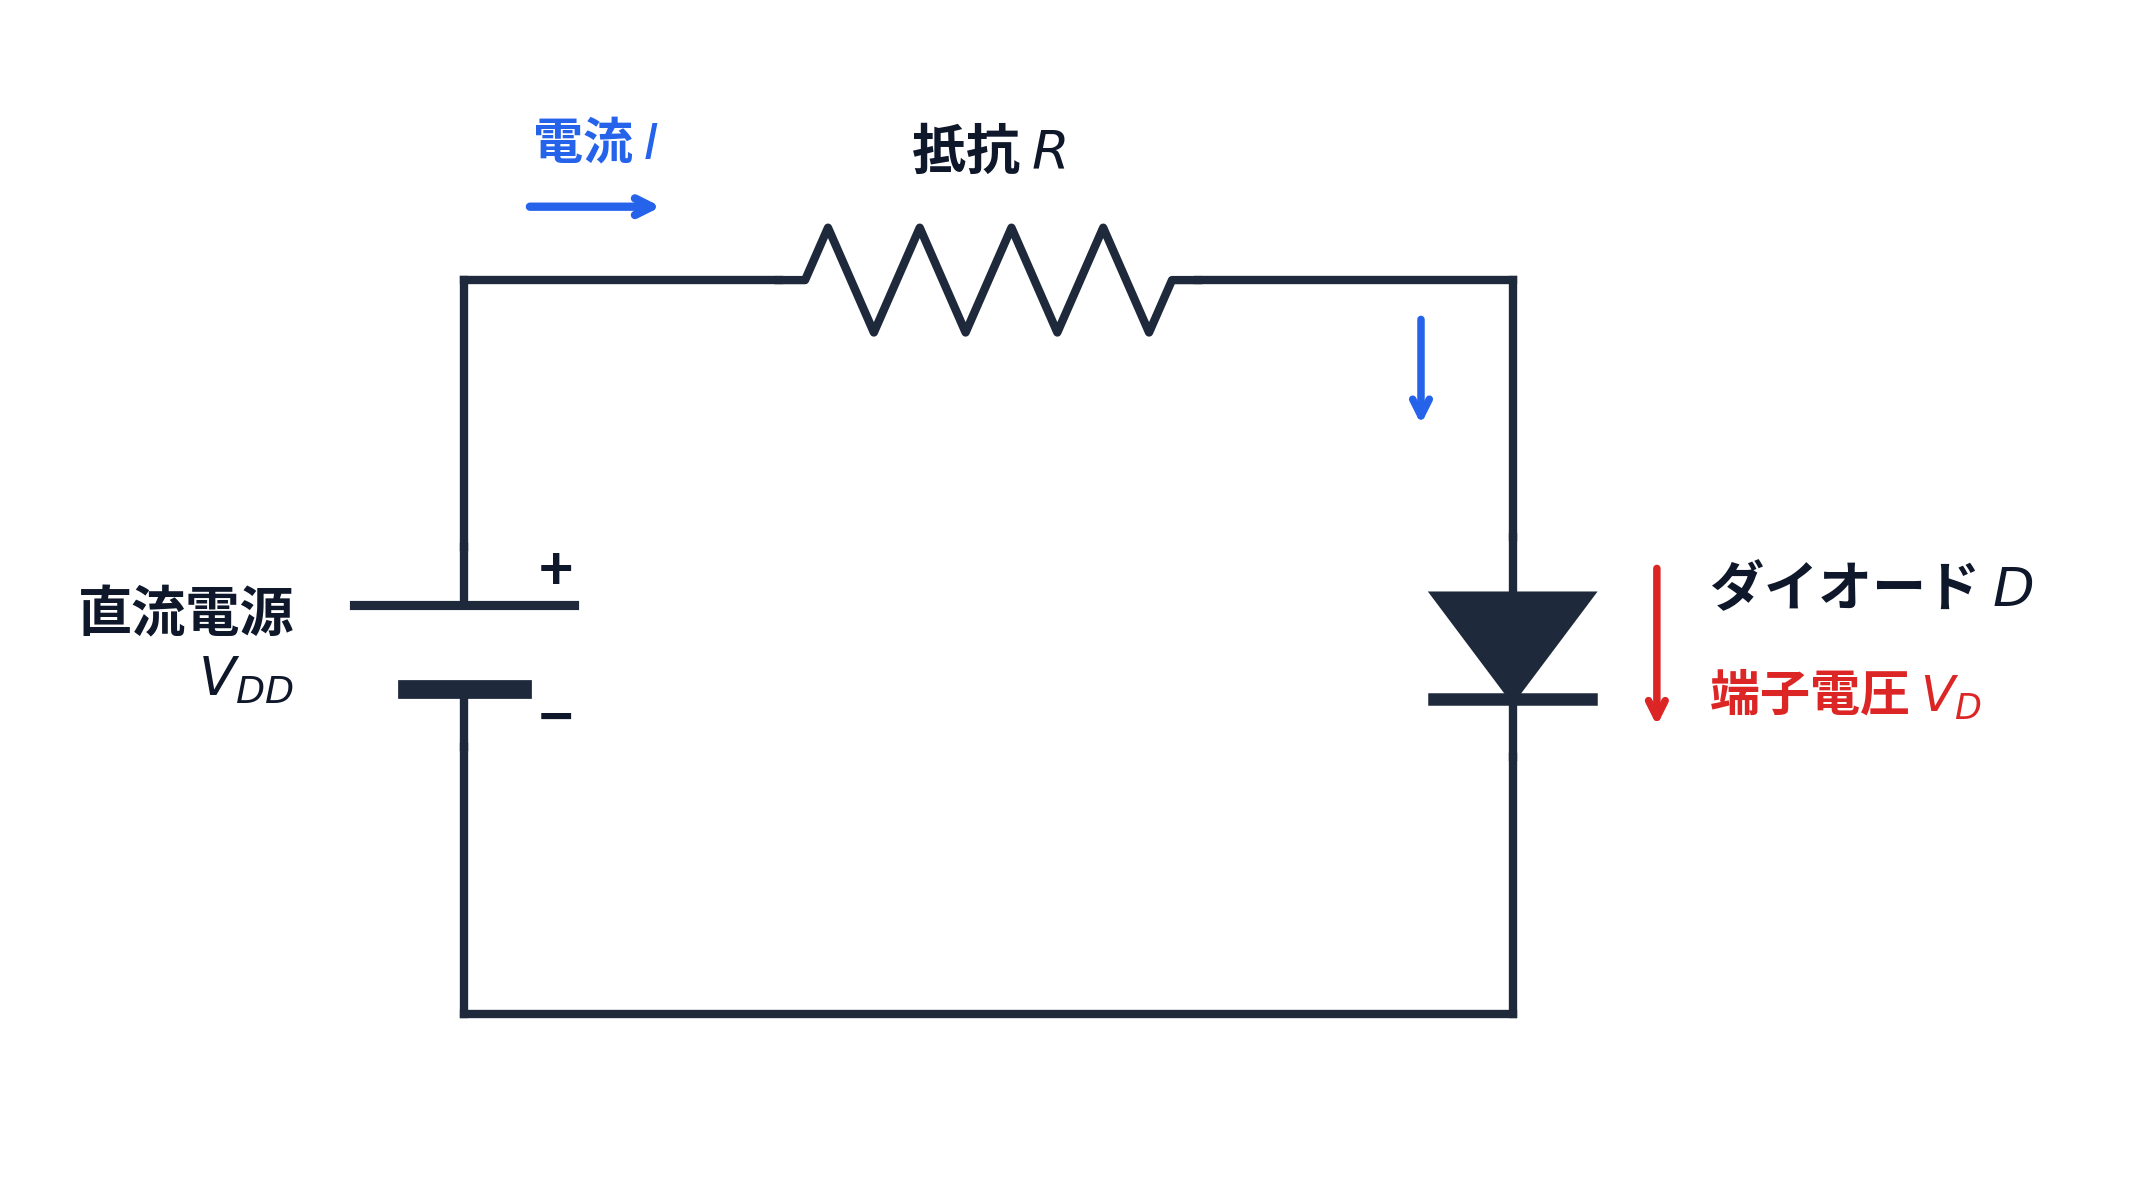

- 直流電源電圧: $V_{DD} = 5.0\,\text{V}$
- 電流制限抵抗: $R = 1.0\,\text{k}\Omega = 1000\,\Omega$
- ダイオード端子電圧: $V_D$
- 回路に流れる電流: $I$

1. **キルヒホッフの第2法則（KVL: 電圧則）**  
   回路を一周すると、電源電圧は抵抗での電圧降下 $R I$ とダイオードの端子電圧 $V_D$ の和になります：
   $$ V_{DD} = R I + V_D \implies I = \frac{V_{DD} - V_D}{R} \quad \text{（抵抗の負荷線：線形方程式）} $$

2. **ショックレーのダイオード方程式（特性方程式）**  
   半導体物理学において、ダイオードに流れる電流と端子電圧は次の**指数関数**で表されます：
   $$ I = I_S \left( e^{\frac{V_D}{n V_T}} - 1 \right) \quad \text{（ダイオードの特性曲線）} $$
   - $I_S$: 逆方向飽和電流（約 $10^{-12}\,\text{A} = 1\,\text{pA}$）
   - $V_T$: 熱電圧（室温 $300\,\text{K}$ において $V_T = \frac{k_B T}{q} \approx 0.026\,\text{V} = 26\,\text{mV}$）
   - $n$: 理想係数（エミッション係数、約 $1.0$）

---

### ❓ なぜ手計算（解析解）で解けないのか？
ダイオードの式を電圧則に代入すると：
$$ V_{DD} = R \cdot I_S \left( e^{\frac{V_D}{n V_T}} - 1 \right) + V_D $$
この方程式には、**多項式 $V_D$ と 指数関数 $e^{V_D}$ が混ざり合っているため、初等関数の式変形で $V_D =$ の形に解くことが数学的に不可能です。**

そのため、「グラフ用紙にあらかじめ印刷された特性曲線の上に負荷線を引き、その交点を目視で読み取る」という近似解法をすることになります。（経験がある人もいるのではないでしょうか。）

---

### ⚡ 回路シミュレータ（SPICEなど）の動作原理：ニュートン法
集積回路（LSI）の設計ソフトは、何百万ものトランジスタやダイオードの動作点を瞬時に決定する必要があります。

回路方程式を電流 $I$ について整理すると：
$$ f(I) = V_{DD} - R I - n V_T \ln\left(\frac{I}{I_S} + 1 \right) = 0 $$

この導関数は：
$$ f'(I) = -R - \frac{n V_T}{I + I_S} $$

- 抵抗 $R = 1000 > 0$, 電流 $I \ge 0$ であるため、**導関数は全領域で常に $f'(I) \le -1000 < 0$！**
- **傾きがゼロになる点（$f'=0$）が物理的にも数学的にも絶対に存在しません。**
- 極値や変曲点によるうねりがなく、単調減少かつ上凸です。

したがって、**ニュートン法の3大条件を満たし、どんな初期値からでもわずか 3〜4 ステップで瞬時に厳密な動作点に完全収束します。**


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# 回路パラメータ
V_DD = 5.0       # 電源電圧: 5.0 V
R = 1000.0       # 抵抗: 1000 Ω (1 kΩ)
I_S = 1.0e-12    # 逆方向飽和電流: 1 pA (10^-12 A)
V_T = 0.026      # 熱電圧: 26 mV
n = 1.0          # 理想係数

# キルヒホッフ則とダイオード特性から導いた電流 I の方程式
def f_circuit(I):
    # 電源電圧 - 抵抗の電圧降下 - ダイオードの端子電圧 = 0
    return V_DD - R * I - n * V_T * math.log(I / I_S + 1.0)

def df_circuit(I):
    # 導関数: 常に -R 以下（傾きゼロに絶対ならない！）
    return -R - (n * V_T) / (I + I_S)

# ニュートン法で動作電流 I を求める（初期値: I0 = 1 mA）
I_current = 0.001
print("=== ダイオード回路の動作点解析（ニュートン法） ===")
print(f"初期推測電流: I_0 = {I_current * 1000:.3f} mA")
print("-" * 65)

for step in range(1, 8):
    f_val = f_circuit(I_current)
    slope = df_circuit(I_current)
    I_next = I_current - f_val / slope
    change = abs(I_next - I_current)
    
    print(f"Step {step}: 電流 I = {I_next * 1000:11.8f} mA (変化量: {change * 1000:.2e} mA)")
    
    if change < 1e-14:
        print("-" * 65)
        print(f"🎉 わずか {step} 回で倍精度限界まで完全収束！\n")
        break
    I_current = I_next

# 求まった動作点での各電圧を計算
I_opt = I_current
V_D_opt = n * V_T * math.log(I_opt / I_S + 1.0)  # ダイオード端子電圧
V_R_opt = R * I_opt                              # 抵抗にかかる電圧

print(f"🎯 計算された動作電流 I_D  = {I_opt * 1000:.4f} mA")
print(f"🎯 ダイオードの端子電圧 V_D = {V_D_opt:.4f} V （シリコンの順方向電圧 約0.58V と一致）")
print(f"🎯 抵抗の電圧降下 V_R     = {V_R_opt:.4f} V")
print(f"検算: V_D + V_R = {V_D_opt + V_R_opt:.4f} V （電源電圧 {V_DD:.1f} V と完全に一致！）")


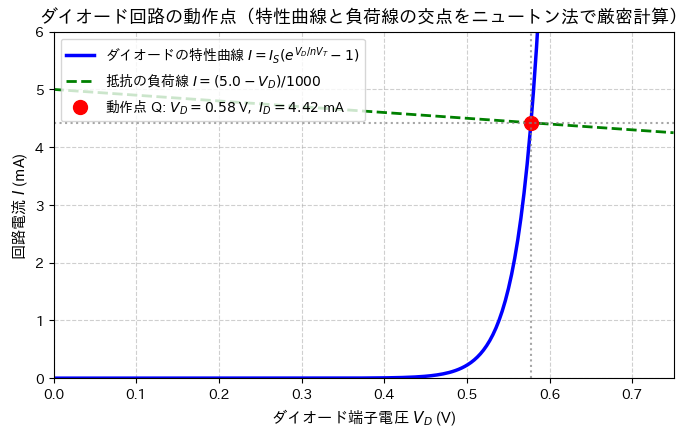

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import math
import japanize_matplotlib

# ダイオード特性曲線と負荷線の交点（動作点 Q）の可視化
v_range = np.linspace(0.0, 0.75, 200)

# 1. ダイオードの特性曲線 (mA 単位)
i_diode_curve = I_S * (np.exp(v_range / (n * V_T)) - 1.0) * 1000.0

# 2. 抵抗の負荷線: I = (V_DD - V_D) / R (mA 単位)
i_load_line = (V_DD - v_range) / R * 1000.0

plt.figure(figsize=(8, 4.5))
plt.plot(v_range, i_diode_curve, 'b-', linewidth=2.5, label='ダイオードの特性曲線 $I = I_S(e^{V_D/nV_T} - 1)$')
plt.plot(v_range, i_load_line, 'g--', linewidth=2, label=f'抵抗の負荷線 $I = ({V_DD:.1f} - V_D) / {int(R)}$')

# ニュートン法で求めた交点（動作点 Q）
plt.plot(V_D_opt, I_opt * 1000, 'ro', markersize=10,
         label=f'動作点 Q: $V_D = {V_D_opt:.2f}$ V,  $I_D = {I_opt*1000:.2f}$ mA')

# 補助線
plt.axvline(V_D_opt, color='gray', linestyle=':', alpha=0.7)
plt.axhline(I_opt * 1000, color='gray', linestyle=':', alpha=0.7)

plt.title("ダイオード回路の動作点（特性曲線と負荷線の交点をニュートン法で厳密計算）", fontsize=13)
plt.xlabel("ダイオード端子電圧 $V_D$ (V)", fontsize=11)
plt.ylabel("回路電流 $I$ (mA)", fontsize=11)
plt.xlim(0.0, 0.75)
plt.ylim(0.0, 6.0)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="upper left", fontsize=10)
plt.show()


---
## 8. まとめ：二分法 vs ニュートン法

第2回の「二分法」と、今回の「ニュートン法」、2つの手法の決定的な特徴を整理します。

### アルゴリズムの比較まとめ

| 特徴 | 二分法 (Bisection Method) | ニュートン法 (Newton-Raphson Method) |
| :--- | :--- | :--- |
| **収束スピード** | 1次収束（1桁に約3.3回反復、低速） | **2次収束（1反復ごとに有効桁数が倍増、圧倒的に高速）** |
| **微分の要否** | **導関数不要（関数の値 $f(x)$ だけでOK）** | 導関数 $f'(x)$ が必須 |
| **収束の安全性** | **100% 絶対安全（解を挟めば必ず収束）** | 初期値依存（傾きゼロで吹き飛ぶ・発散のリスクあり） |
| **最適な適用シーン** | 関数が複雑・ブラックボックスな場合、<br>絶対に失敗が許されない安全重視の基幹システム | **3大条件を満たす問題**：<br>① CPUの逆数・平方根計算<br>② 電子回路の動作点解析 |
